In [7]:
"""
Addestramento YOLO segmentazione su DeepFashion2, in locale.

Uso:
    python train_local.py            # prepara i dati (solo la prima volta) e addestra
    python train_local.py --test     # prova veloce: 5% dei dati, 1 epoca

Se si interrompe, rilancia lo stesso comando: riparte da last.pt.
"""
import random
import shutil
import sys
from pathlib import Path

from ultralytics import YOLO

# ======================= CONFIGURAZIONE =======================
IMAGES       = Path("train/image/image")         # cartella con i .jpg scaricati
LABELS       = Path("train/labels_seg")    # cartella con i .txt
WORK         = Path("df2")                # qui viene creata la struttura per YOLO
MODEL        = "yolo26s-seg.pt"           # o il percorso del tuo .pt
VAL_FRACTION = 0.05
HOURS        = 10
SEED         = 0
EPOCHS       = 30
IMGSZ        = 640
BATCH        = 16     # -1 = YOLO sceglie da solo in base alla VRAM (~60%)
WORKERS      = 2      # abbassa a 2 se la RAM si riempie
FRACTION     = 1.0
# ==============================================================

NAMES = ["short_sleeved_shirt", "long_sleeved_shirt", "short_sleeved_outwear",
         "long_sleeved_outwear", "vest", "sling", "shorts", "trousers", "skirt",
         "short_sleeved_dress", "long_sleeved_dress", "vest_dress", "sling_dress"]

PROJECT = Path("runs").resolve()   # assoluto: altrimenti YOLO salva in runs/segment/runs/...
RUN = PROJECT / "df2"


def prepare():
    """Sposta immagini ed etichette in WORK/images|labels/train|val (una volta sola)."""
    yaml = WORK / "data.yaml"
    if yaml.exists():
        return yaml

    imgs = {p.stem: p for p in IMAGES.glob("*.jpg")}
    lbls = {p.stem: p for p in LABELS.glob("*.txt")}
    common = sorted(imgs.keys() & lbls.keys())
    print(f"Immagini {len(imgs)}, etichette {len(lbls)}, coppie {len(common)}")
    if not common and not (WORK / "images" / "train").exists():
        sys.exit(f"Nessuna coppia trovata: controlla IMAGES={IMAGES} e LABELS={LABELS}")

    random.Random(SEED).shuffle(common)
    n_val = max(1, int(len(common) * VAL_FRACTION))
    splits = {"val": common[:n_val], "train": common[n_val:]}

    for sp, items in splits.items():
        (WORK / "images" / sp).mkdir(parents=True, exist_ok=True)
        (WORK / "labels" / sp).mkdir(parents=True, exist_ok=True)
        for i, stem in enumerate(items, 1):
            # spostare sullo stesso disco è istantaneo e non occupa spazio in più
            shutil.move(imgs[stem], WORK / "images" / sp / f"{stem}.jpg")
            shutil.move(lbls[stem], WORK / "labels" / sp / f"{stem}.txt")
            if i % 20000 == 0:
                print(f"  {sp}: {i}/{len(items)}")
        print(f"{sp}: {len(items)} immagini")

    yaml.write_text(
        f"path: {WORK.resolve().as_posix()}\ntrain: images/train\nval: images/val\n\nnames:\n"
        + "".join(f"  {i}: {n}\n" for i, n in enumerate(NAMES)),
        encoding="utf-8",   # altrimenti le lettere accentate nel percorso (es. "Università") si perdono
    )
    return yaml


def main():
    test = "--test" in sys.argv
    yaml = prepare()
    last = RUN / "weights" / "last.pt"

    if last.exists() and not test:
        print(f"Riprendo da {last}")
        YOLO(last).train(resume=True)
    else:
        YOLO(MODEL).train(
            data=str(yaml),
            epochs=1 if test else EPOCHS,
            time = HOURS,
            fraction=0.05 if test else FRACTION,
            imgsz=IMGSZ,
            batch=BATCH,
            workers=WORKERS,
            device=0,
            cache=False,
            project=str(PROJECT),
            name="df2-test" if test else "df2",
            exist_ok=True,
        )

    if not test:
        best = YOLO(RUN / "weights" / "best.pt")
        m = best.val(data=str(yaml), imgsz=IMGSZ)
        print(f"mAP50-95 box: {m.box.map:.4f}   mask: {m.seg.map:.4f}")
        print(f"Pesi in {RUN / 'weights'}")


# Su Windows il blocco qui sotto è obbligatorio: senza, i worker del dataloader
# rilanciano lo script all'infinito.
if __name__ == "__main__":
    main()

New https://pypi.org/project/ultralytics/8.4.198 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.51  Python-3.12.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=df2\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

In [35]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

path = "test/test/image/000037.jpg"
model = YOLO("runs/df2/weights/best.pt")
results = model.predict(path)
img = results[0]
annotated = img.plot()


image 1/1 C:\Users\UTENTE\Documents\Universit\Computer Vision\Progetto\test\test\image\000037.jpg: 640x480 1 short_sleeved_shirt, 110.5ms
Speed: 2.3ms preprocess, 110.5ms inference, 9.2ms postprocess per image at shape (1, 3, 640, 480)


In [37]:
class_ids = img.boxes.cls.cpu().numpy().astype(int)

names = [model.names[class_id] for class_id in class_ids]

print(names)

['short_sleeved_shirt']


In [39]:
%matplotlib inline

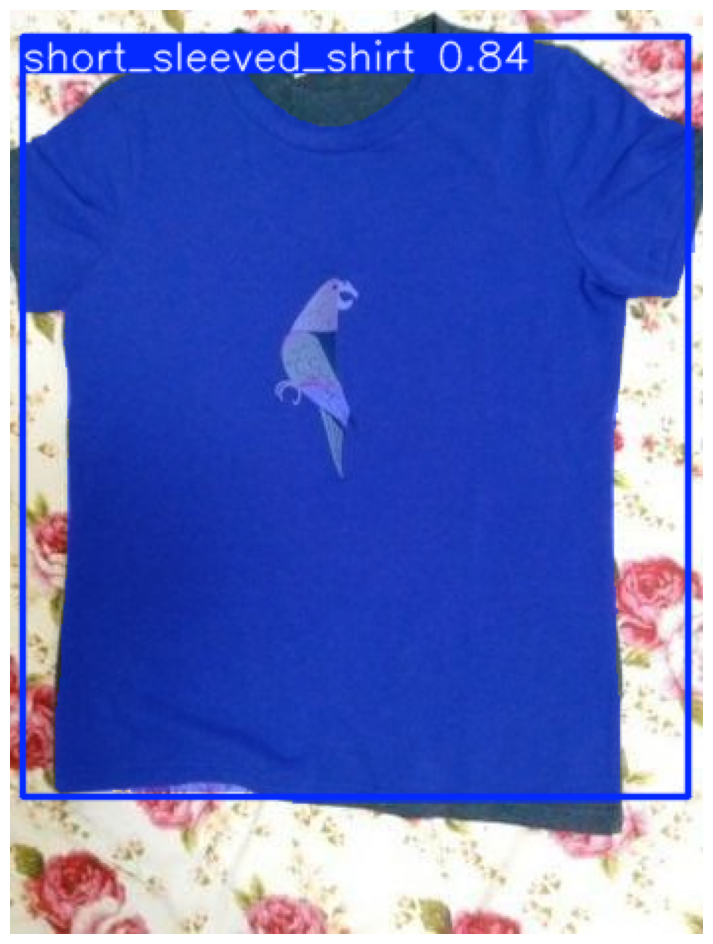

In [41]:
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()